# Colon Cancer Classification - 4 Architectures

**Pipeline:** Import Libraries -> Load Dataset -> EDA -> Visualization -> Data Cleaning ->
Train-Test Split -> Train/Evaluate Model 1..4 -> Model Comparison -> Final Evaluation ->
Explainability (Grad-CAM) -> Save Model

| # | Architecture | Optimizer | Epochs | Backbone |
|---|---|---|---|---|
| 1 | CNN | Adam | 5 | from scratch |
| 2 | MobileNet | Adam | 3 | frozen |
| 3 | VGG19 | Adam | 5 | frozen |
| 4 | ResNet50 | Adam | 5 | frozen |

All metrics (accuracy, precision, recall, F1, AUC, training time) are written automatically to
`Results/colon/` on Google Drive: `comparison.csv`, `all_results.json`, `summary.xlsx`,
plus training curves and confusion matrices as images.


## Dataset

Source: `andrewmvd/lung-and-colon-cancer-histopathological-images` (5000 images per class). The two class folders must sit directly inside `Colon Dataset`.

**Expected Drive layout:**
```
MyDrive/
└── Colab Notebooks/
    └── My Projects/
        └── Cancer Detection/
            ├── Colon Dataset/
            │   ├── Adenocarcinoma/
            │   ├── Benign Tissue/
            ├── Results/     (created automatically)
            └── Deploy/      (created automatically)
```

If your project folder has a different name, change `PROJECT_DIR` in the next cell.

In [ ]:
# ============================================================
#  0) Mount Google Drive and configure the project
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os

# ---------- Edit these two lines only ----------
PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/My Projects'
DATA_PATH   = f'{PROJECT_DIR}/Colon Dataset'
# -----------------------------------------------

CANCER_TYPE = 'colon'
IMG_SIZE    = 256          # same value across all four notebooks
BATCH_SIZE  = 64
SPLIT       = 0.2
SEED        = 2022

# Number of epochs per model (identical to the original scripts)
EPOCHS = {
    "CNN": 5,
    "MobileNet": 3,
    "VGG19": 5,
    "ResNet50": 5
}

RESULTS_DIR = f'{PROJECT_DIR}/Results/{CANCER_TYPE}'
for sub in ['', '/models', '/figures', '/histories', '/reports', '/predictions']:
    os.makedirs(RESULTS_DIR + sub, exist_ok=True)

assert os.path.isdir(DATA_PATH), f'Path not found: {DATA_PATH}'
print('DATA_PATH   :', DATA_PATH)
print('RESULTS_DIR :', RESULTS_DIR)
print('Dataset folders:', sorted(os.listdir(DATA_PATH))[:10])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_PATH   : /content/drive/MyDrive/Colab Notebooks/My Projects/Colon Dataset
RESULTS_DIR : /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
Dataset folders: ['Adenocarcinoma', 'Benign Tissue']


## 1) Import Libraries

In [ ]:
# ============================================================
#  1) Import Libraries
# ============================================================
import os, gc, json, time, hashlib, warnings
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.applications import MobileNet, ResNet50
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

warnings.filterwarnings('ignore')
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow :', tf.__version__)
print('Keras      :', tf.keras.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))


TensorFlow : 2.20.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Load Dataset

In [ ]:
# ============================================================
#  2) Load Dataset - build a filepath/label table
# ============================================================
CLASS_DIRS = {
    "Adenocarcinoma": "Colon adenocarcinoma",
    "Benign Tissue": "Colon benign"
}          # folder name -> final class label
CLASS_NAMES = list(CLASS_DIRS.values())
NUM_CLASSES = len(CLASS_NAMES)

rows = []
for folder, label in CLASS_DIRS.items():
    files = []
    for ext in ('*.jpeg', '*.jpg', '*.png', '*.JPG', '*.JPEG', '*.PNG', '*.tif', '*.bmp'):
        files += glob(os.path.join(DATA_PATH, folder, ext))
    if len(files) == 0:
        raise FileNotFoundError(f'No images found in: {os.path.join(DATA_PATH, folder)}')
    for f in files:
        rows.append({'filepath': f, 'label': label})

df = pd.DataFrame(rows).reset_index(drop=True)

# Fixed class ordering, so the label mapping never flips between sessions
LABEL2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
df['label_idx'] = df['label'].map(LABEL2IDX)

with open(f'{RESULTS_DIR}/class_names.json', 'w') as fh:
    json.dump({'cancer_type': CANCER_TYPE, 'class_names': CLASS_NAMES,
               'label2idx': LABEL2IDX, 'img_size': IMG_SIZE}, fh, indent=2)

print(f'Total images: {len(df)} | Classes: {NUM_CLASSES}')
df.head()


Total images: 10000 | Classes: 2


,filepath,label,label_idx
0,/content/drive/MyDrive/Colab Notebooks/My Proj...,Colon adenocarcinoma,0
1,/content/drive/MyDrive/Colab Notebooks/My Proj...,Colon adenocarcinoma,0
2,/content/drive/MyDrive/Colab Notebooks/My Proj...,Colon adenocarcinoma,0
3,/content/drive/MyDrive/Colab Notebooks/My Proj...,Colon adenocarcinoma,0
4,/content/drive/MyDrive/Colab Notebooks/My Proj...,Colon adenocarcinoma,0


## 3) EDA

In [ ]:
# ============================================================
#  3) EDA - Exploratory Data Analysis
# ============================================================
print('Class distribution:')
print(df['label'].value_counts(), '\n')

counts = df['label'].value_counts()
imbalance = counts.max() / counts.min()
print(f'Imbalance ratio (max/min): {imbalance:.2f}')

# Inspect image dimensions and color modes on a sample
sample = df.sample(min(120, len(df)), random_state=SEED)
info = []
for p in sample['filepath']:
    try:
        with Image.open(p) as im:
            info.append({'width': im.size[0], 'height': im.size[1], 'mode': im.mode,
                         'kb': os.path.getsize(p) / 1024})
    except Exception:
        pass
info = pd.DataFrame(info)
print('\nImage dimensions (sample):')
print(info[['width', 'height', 'kb']].describe().T[['mean', 'min', 'max']])
print('\nColor modes:', info['mode'].value_counts().to_dict())

eda_summary = {
    'n_images': int(len(df)),
    'n_classes': int(NUM_CLASSES),
    'class_counts': counts.to_dict(),
    'imbalance_ratio': float(imbalance),
    'width_mean': float(info['width'].mean()), 'height_mean': float(info['height'].mean()),
    'color_modes': {k: int(v) for k, v in info['mode'].value_counts().to_dict().items()},
}
with open(f'{RESULTS_DIR}/reports/eda_summary.json', 'w') as fh:
    json.dump(eda_summary, fh, indent=2)
eda_summary


Class distribution:
label
Colon adenocarcinoma    5000
Colon benign            5000
Name: count, dtype: int64 

Imbalance ratio (max/min): 1.00

Image dimensions (sample):
              mean         min         max
width   768.000000  768.000000  768.000000
height  768.000000  768.000000  768.000000
kb       94.349333   62.998047  133.725586

Color modes: {'RGB': 120}


{'n_images': 10000,
 'n_classes': 2,
 'class_counts': {'Colon adenocarcinoma': 5000, 'Colon benign': 5000},
 'imbalance_ratio': 1.0,
 'width_mean': 768.0,
 'height_mean': 768.0,
 'color_modes': {'RGB': 120}}

## 4) Visualization

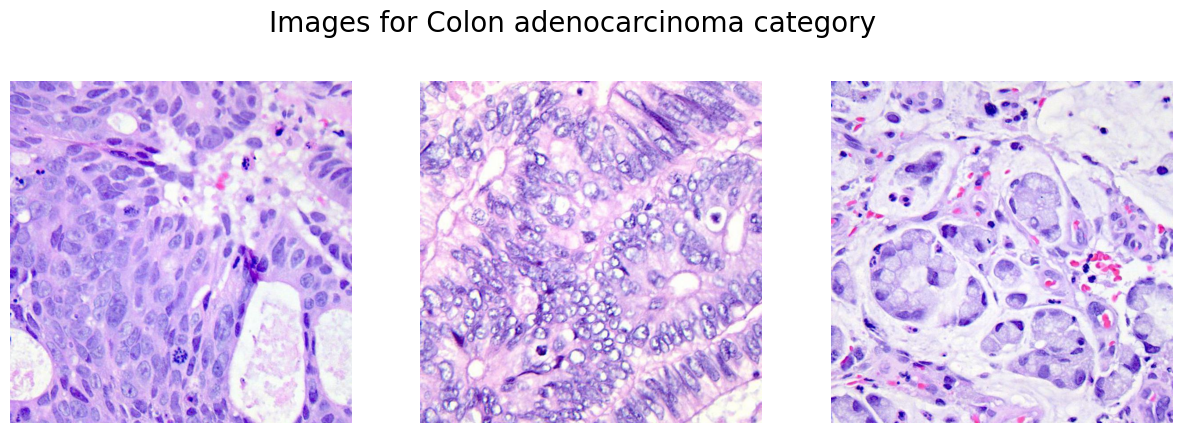

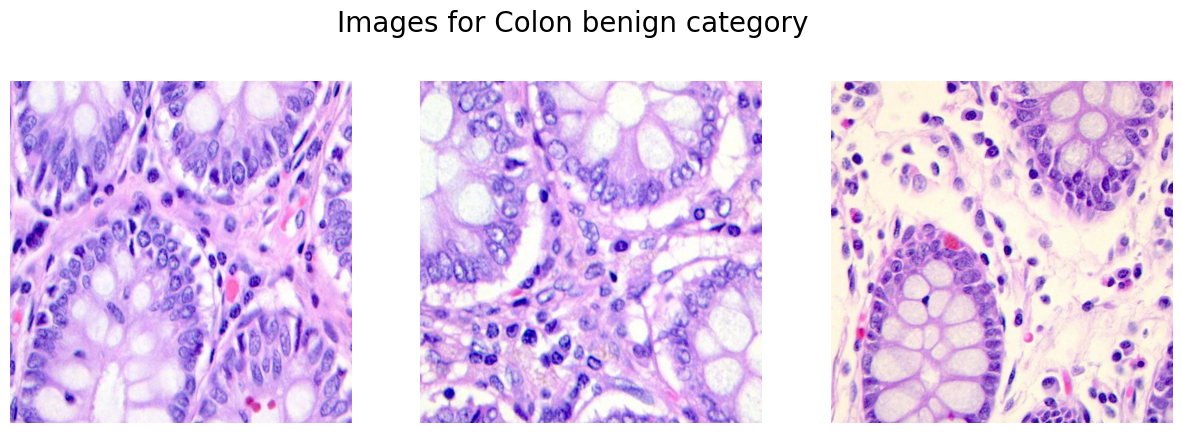

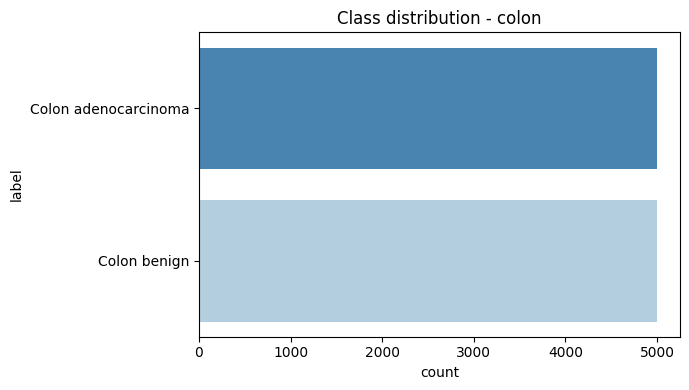

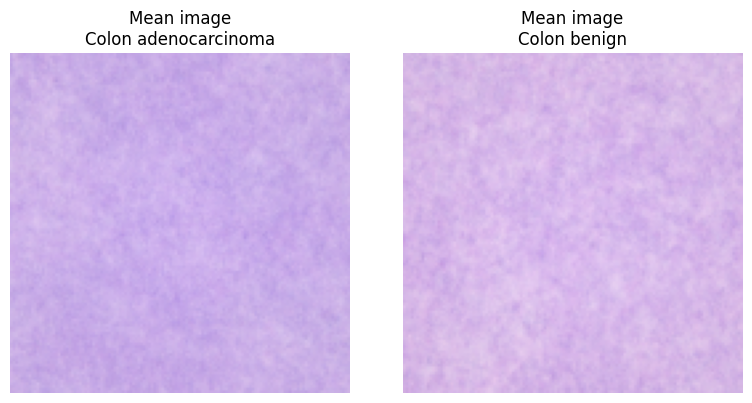

In [ ]:
# ============================================================
#  4) Visualization
# ============================================================
# 4.1 Random samples per class
for cls in CLASS_NAMES:
    paths = df[df.label == cls]['filepath'].sample(3, random_state=SEED).tolist()
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Images for {cls} category', fontsize=20)
    for i, p in enumerate(paths):
        ax[i].imshow(np.array(Image.open(p)))
        ax[i].axis('off')
    plt.show()

# 4.2 Class distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, y='label', order=CLASS_NAMES, palette='Blues_r')
plt.title(f'Class distribution - {CANCER_TYPE}')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/class_distribution.png', dpi=120)
plt.show()

# 4.3 Mean image per class - shows color/texture differences between classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4))
axes = np.atleast_1d(axes)
for ax, cls in zip(axes, CLASS_NAMES):
    ps = df[df.label == cls]['filepath'].sample(min(60, (df.label == cls).sum()),
                                                random_state=SEED)
    acc = np.zeros((128, 128, 3), dtype=np.float64)
    for p in ps:
        acc += cv2.cvtColor(cv2.resize(cv2.imread(p), (128, 128)), cv2.COLOR_BGR2RGB)
    ax.imshow((acc / len(ps)).astype('uint8'))
    ax.set_title(f'Mean image\n{cls}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/mean_image_per_class.png', dpi=120)
plt.show()


## 5) Data Cleaning

In [ ]:
# # ============================================================
# #  5) Data Cleaning
# # ============================================================
# # (a) Detect corrupted or unreadable images
# bad = []
# for p in df['filepath']:
#     try:
#         with Image.open(p) as im:
#             im.verify()
#     except Exception:
#         bad.append(p)
# print(f'Corrupted images: {len(bad)}')

# # (b) Detect exact duplicates by file hash
# def file_hash(path, chunk=1 << 20):
#     h = hashlib.md5()
#     with open(path, 'rb') as fh:
#         while True:
#             b = fh.read(chunk)
#             if not b:
#                 break
#             h.update(b)
#     return h.hexdigest()

# df['hash'] = df['filepath'].apply(file_hash)
# dup_mask = df.duplicated('hash', keep='first')
# print(f'Duplicate images: {int(dup_mask.sum())}')

# # (c) Identical images assigned to different classes -> label conflict, always removed
# conflict = (df.groupby('hash')['label'].nunique() > 1)
# conflict_hashes = set(conflict[conflict].index)
# print(f'Label conflicts: {len(conflict_hashes)} hashes')

# DROP_DUPLICATES = True     # set to False to keep the dataset exactly as-is

# clean_log = {'corrupted': len(bad), 'duplicates': int(dup_mask.sum()),
#              'label_conflicts': len(conflict_hashes), 'drop_duplicates': DROP_DUPLICATES,
#              'n_before': int(len(df))}

# df = df[~df['filepath'].isin(bad)]
# df = df[~df['hash'].isin(conflict_hashes)]
# if DROP_DUPLICATES:
#     df = df[~df.duplicated('hash', keep='first')]
# df = df.drop(columns=['hash']).reset_index(drop=True)

# clean_log['n_after'] = int(len(df))
# with open(f'{RESULTS_DIR}/reports/cleaning_log.json', 'w') as fh:
#     json.dump(clean_log, fh, indent=2)

# print('\nAfter cleaning:', len(df), 'images')
# print(df['label'].value_counts())


## 6) Train-Test Split

In [ ]:
# ============================================================
#  6) Train-Test Split - images loaded into memory (same as original script)
# ============================================================
# Memory note: images are kept as uint8 to avoid exhausting the Colab session.
X, Y = [], []
for p, y in zip(df['filepath'].values, df['label_idx'].values):
    img = cv2.imread(p)                       # BGR, 0-255, same as the original training
    if img is None:
        continue
    X.append(cv2.resize(img,1 (IMG_SIZE, IMG_SIZE)))
    Y.append(y)

X = np.asarray(X, dtype='uint8')
Y = np.asarray(Y)
one_hot_encoded_Y = pd.get_dummies(Y).values.astype('float32')
print('X:', X.shape, '| Y:', one_hot_encoded_Y.shape)

X_train, X_val, Y_train, Y_val = train_test_split(
    X, one_hot_encoded_Y, test_size=SPLIT, random_state=SEED, stratify=Y)

del X, Y
gc.collect()

# Ground truth kept in a separate variable so Y_val is never overwritten
y_true_val = np.argmax(Y_val, axis=1)

print(X_train.shape, X_val.shape)
print('Validation distribution:',
      dict(zip(CLASS_NAMES, np.bincount(y_true_val, minlength=NUM_CLASSES))))


X: (10000, 256, 256, 3) | Y: (10000, 2)
(8000, 256, 256, 3) (2000, 256, 256, 3)
Validation distribution: {'Colon adenocarcinoma': np.int64(1000), 'Colon benign': np.int64(1000)}


## 7) Evaluation helpers and result logging

This cell defines `evaluate_and_log()`, called after every model. It writes:
- `comparison.csv` - one row per model with every metric
- `all_results.json` - full classification report and confusion matrix
- `summary.xlsx` - comparison sheet plus one sheet per model
- `figures/` - training curves and confusion matrices

In [ ]:
# ============================================================
#  7) Evaluation helpers and result logging
# ============================================================
COMPARISON_CSV = f'{RESULTS_DIR}/comparison.csv'
ALL_RESULTS_JSON = f'{RESULTS_DIR}/all_results.json'
SUMMARY_XLSX = f'{RESULTS_DIR}/summary.xlsx'

def _load_all_results():
    if os.path.exists(ALL_RESULTS_JSON):
        with open(ALL_RESULTS_JSON) as fh:
            return json.load(fh)
    return {}

def plot_history(model_name, history):
    """Plot and save loss/accuracy curves."""
    hdf = pd.DataFrame(history.history)
    hdf.index.name = 'epoch'
    hdf.to_csv(f'{RESULTS_DIR}/histories/{model_name}_history.csv')

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k in ['loss', 'val_loss']:
        if k in hdf: ax[0].plot(hdf[k], label=k, marker='o')
    for k in ['accuracy', 'val_accuracy']:
        if k in hdf: ax[1].plot(hdf[k], label=k, marker='o')
    ax[0].set_title(f'{model_name} - Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_title(f'{model_name} - Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}_history.png', dpi=120)
    plt.show()
    return hdf

def plot_confusion(model_name, cm, normalize=False):
    data = cm.astype('float') / cm.sum(axis=1, keepdims=True) if normalize else cm
    plt.figure(figsize=(1.6 * NUM_CLASSES + 4, 1.4 * NUM_CLASSES + 3))
    sns.heatmap(data, annot=True, fmt='.2f' if normalize else 'd', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}' + (' (normalized)' if normalize else ''))
    plt.tight_layout()
    suffix = '_cm_norm' if normalize else '_cm'
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}{suffix}.png', dpi=120)
    plt.show()

def evaluate_and_log(model_name, model, y_true, y_prob, history=None,
                     train_time=None, notes=''):
    """Compute every metric, plot it, and persist it to CSV/JSON/XLSX."""
    y_pred = np.argmax(y_prob, axis=1)

    acc = metrics.accuracy_score(y_true, y_pred)
    p_ma, r_ma, f_ma, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    p_w, r_w, f_w, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)
    try:
        auc = (metrics.roc_auc_score(y_true, y_prob[:, 1]) if NUM_CLASSES == 2
               else metrics.roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'))
    except Exception:
        auc = float('nan')

    cm = metrics.confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    rep = metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, output_dict=True,
                                        zero_division=0)

    print(metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, zero_division=0))
    plot_confusion(model_name, cm)
    plot_confusion(model_name, cm, normalize=True)
    if history is not None:
        plot_history(model_name, history)

    # ---- persist ----
    pd.DataFrame(rep).T.to_csv(f'{RESULTS_DIR}/reports/{model_name}_classification_report.csv')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        f'{RESULTS_DIR}/reports/{model_name}_confusion_matrix.csv')
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_prob.npy', y_prob)
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_true.npy', y_true)

    row = {
        'cancer_type': CANCER_TYPE, 'model': model_name,
        'accuracy': round(float(acc), 4),
        'precision_macro': round(float(p_ma), 4), 'recall_macro': round(float(r_ma), 4),
        'f1_macro': round(float(f_ma), 4),
        'precision_weighted': round(float(p_w), 4), 'recall_weighted': round(float(r_w), 4),
        'f1_weighted': round(float(f_w), 4),
        'auc': round(float(auc), 4) if auc == auc else None,
        'train_time_sec': round(float(train_time), 1) if train_time else None,
        'epochs': int(len(history.history['loss'])) if history is not None else None,
        'total_params': int(model.count_params()),
        'trainable_params': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE, 'n_eval_samples': int(len(y_true)),
        'notes': notes,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
    }
    for c in CLASS_NAMES:
        row[f'f1__{c}'] = round(float(rep[c]['f1-score']), 4)
        row[f'recall__{c}'] = round(float(rep[c]['recall']), 4)

    all_results = _load_all_results()
    all_results[model_name] = {'summary': row, 'classification_report': rep,
                               'confusion_matrix': cm.tolist()}
    with open(ALL_RESULTS_JSON, 'w') as fh:
        json.dump(all_results, fh, indent=2)

    comp = pd.DataFrame([v['summary'] for v in all_results.values()])
    comp = comp.sort_values('f1_macro', ascending=False).reset_index(drop=True)
    comp.to_csv(COMPARISON_CSV, index=False)
    try:
        with pd.ExcelWriter(SUMMARY_XLSX, engine='openpyxl') as xl:
            comp.to_excel(xl, sheet_name='comparison', index=False)
            for m, v in all_results.items():
                pd.DataFrame(v['classification_report']).T.to_excel(xl, sheet_name=m[:28])
    except Exception as e:
        print('XLSX export skipped:', e)

    print(f'\nSaved results for [{model_name}] to {RESULTS_DIR}')
    print(f'accuracy={acc:.4f}  f1_macro={f_ma:.4f}  auc={auc:.4f}')
    return row

def save_model_files(model_name, model):
    """Save the model in both formats."""
    p1 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.keras'
    p2 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.h5'
    model.save(p1); model.save(p2)
    print('Saved:', p1)
    return p1

def free_memory():
    """Release memory between models - important on Colab."""
    tf.keras.backend.clear_session()
    gc.collect()


In [ ]:
# ============================================================
#  Explainability helper: Grad-CAM
# ============================================================
CONV_TYPES = (layers.Conv2D, layers.DepthwiseConv2D, layers.SeparableConv2D)

def _last_conv_index(m):
    for i in range(len(m.layers) - 1, -1, -1):
        if isinstance(m.layers[i], CONV_TYPES):
            return i
    return None

def _gradcam_sequential(model, img, class_idx):
    """For the plain CNN: walk the layers one by one."""
    ci = _last_conv_index(model)
    with tf.GradientTape() as tape:
        x, conv_out = img, None
        for j, lyr in enumerate(model.layers):
            x = lyr(x, training=False)
            if j == ci:
                conv_out = x
                tape.watch(conv_out)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def _gradcam_nested(model, img, class_idx):
    """For models wrapping a pretrained backbone (MobileNet / VGG19 / ResNet50)."""
    base = model.layers[0]
    ci = _last_conv_index(base)
    feat = tf.keras.Model(base.inputs, [base.layers[ci].output, base.output])
    with tf.GradientTape() as tape:
        conv_out, base_out = feat(img, training=False)
        tape.watch(conv_out)
        x = base_out
        for lyr in model.layers[1:]:
            x = lyr(x, training=False)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def make_gradcam_heatmap(img_array, model, class_idx=None):
    img = tf.convert_to_tensor(np.asarray(img_array, dtype='float32'))
    fn = _gradcam_nested if isinstance(model.layers[0], tf.keras.Model) else _gradcam_sequential
    try:
        grads, conv_out, preds, idx = fn(model, img, class_idx)
        pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.reduce_sum(conv_out[0] * pooled, axis=-1)
        heat = tf.maximum(heat, 0) / (tf.reduce_max(heat) + 1e-8)
        return heat.numpy(), preds.numpy()[0], int(idx)
    except Exception as e:
        # Fallback: saliency map (gradient of the output w.r.t. the input image)
        with tf.GradientTape() as tape:
            tape.watch(img)
            preds = model(img, training=False)
            idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
            loss = preds[:, idx]
        g = tape.gradient(loss, img)[0]
        heat = tf.reduce_max(tf.abs(g), axis=-1)
        heat = heat / (tf.reduce_max(heat) + 1e-8)
        print('Grad-CAM unavailable for this model, used saliency instead:', type(e).__name__)
        return heat.numpy(), preds.numpy()[0], int(idx)

def show_gradcam(model, img_disp, img_input, true_label=None, ax=None, alpha=0.4):
    heat, probs, idx = make_gradcam_heatmap(img_input, model)
    heat = cv2.resize(heat.astype('float32'), (img_disp.shape[1], img_disp.shape[0]))
    heat = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(heat * alpha + img_disp * (1 - alpha))
    ax = ax or plt.gca()
    ax.imshow(overlay); ax.axis('off')
    t = f'pred: {CLASS_NAMES[idx]} ({probs[idx]:.2f})'
    if true_label is not None:
        t += f'\ntrue: {true_label}'
    ax.set_title(t, fontsize=10,
                 color=('green' if (true_label is None or true_label == CLASS_NAMES[idx]) else 'red'))


In [ ]:
PREPROCESS_NAME = 'bgr_raw'
print('Preprocessing used during training:', PREPROCESS_NAME)

Preprocessing used during training: bgr_raw


## Model 1: **CNN** - Train

In [ ]:
# ---- Train: CNN ----
MODEL_NAME = 'CNN'
free_memory()

model = keras.models.Sequential([
    layers.Conv2D(filters=32, kernel_size=(5, 5), activation='relu',
                  input_shape=(IMG_SIZE, IMG_SIZE, 3), padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


t0 = time.time()
history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS[MODEL_NAME],
                    verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    33,554,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,684,162 (128.49 MB)

 Trainable params: 33,683,394 (128.49 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 188ms/step - accuracy: 0.8664 - loss: 0.3321 - val_accuracy: 0.5000 - val_loss: 10.7754
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 150ms/step - accuracy: 0.9345 - loss: 0.1692 - val_accuracy: 0.8435 - val_loss: 0.6192
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 152ms/step - accuracy: 0.9580 - loss: 0.1134 - val_accuracy: 0.5000 - val_loss: 22.6848
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.9747 - loss: 0.0716 - val_accuracy: 0.5200 - val_loss: 5.6611
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - accuracy: 0.9830 - loss: 0.0529 - val_accuracy: 0.5000 - val_loss: 61.6177
Training time: 2.0 minutes


### Model 1: **CNN** - Evaluation

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step
                      precision    recall  f1-score   support

Colon adenocarcinoma       0.50      1.00      0.67      1000
        Colon benign       0.00      0.00      0.00      1000

            accuracy                           0.50      2000
           macro avg       0.25      0.50      0.33      2000
        weighted avg       0.25      0.50      0.33      2000



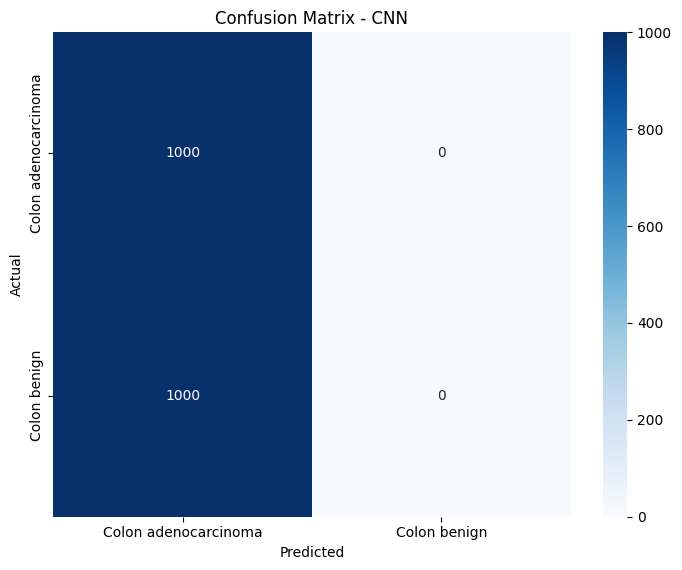

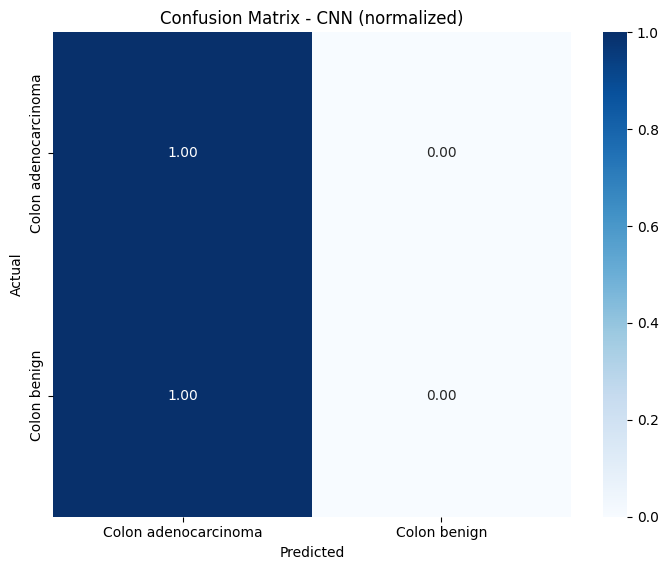

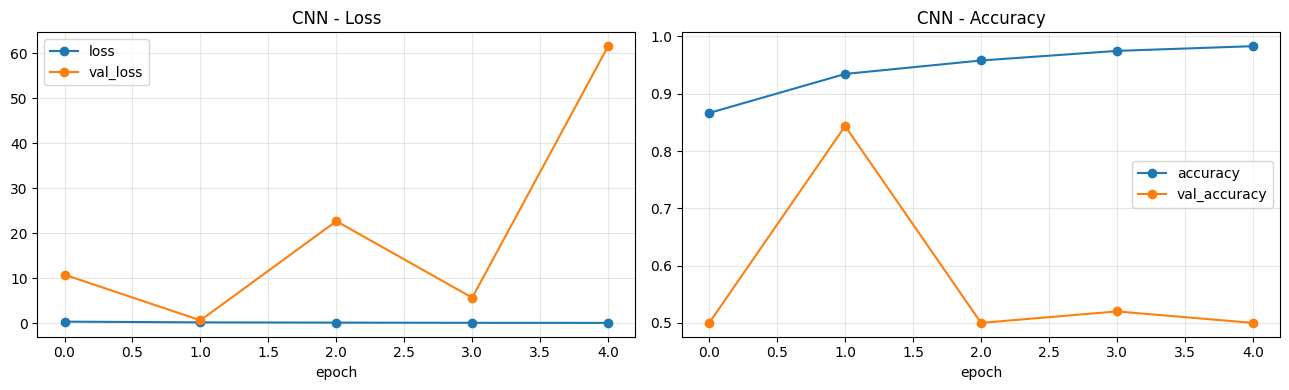


Saved results for [CNN] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
accuracy=0.5000  f1_macro=0.3333  auc=0.5000


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon/models/colon_CNN.keras


In [ ]:
# ---- Evaluation: CNN ----
y_prob = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_val, y_prob, history, train_time,
                 notes='from scratch')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 2: **MobileNet** - Train

In [ ]:
# ---- Train: MobileNet ----
MODEL_NAME = 'MobileNet'
free_memory()

base = MobileNet(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False          # frozen backbone, same as the original script

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


t0 = time.time()
history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS[MODEL_NAME],
                    verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional) │ (None, 8, 8, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,525,954 (13.45 MB)

 Trainable params: 296,322 (1.13 MB)

 Non-trainable params: 3,229,632 (12.32 MB)

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 196ms/step - accuracy: 0.9335 - loss: 0.1620 - val_accuracy: 0.9625 - val_loss: 0.0974
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.9744 - loss: 0.0642 - val_accuracy: 0.9810 - val_loss: 0.0532
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.9835 - loss: 0.0457 - val_accuracy: 0.9740 - val_loss: 0.0604
Training time: 1.1 minutes


### Model 2: **MobileNet** - Evaluation

32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 186ms/step
                      precision    recall  f1-score   support

Colon adenocarcinoma       0.96      0.99      0.97      1000
        Colon benign       0.99      0.95      0.97      1000

            accuracy                           0.97      2000
           macro avg       0.97      0.97      0.97      2000
        weighted avg       0.97      0.97      0.97      2000



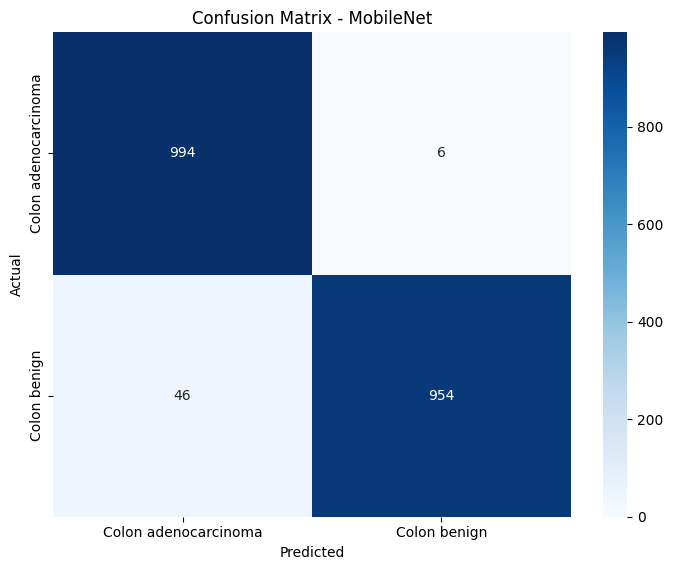

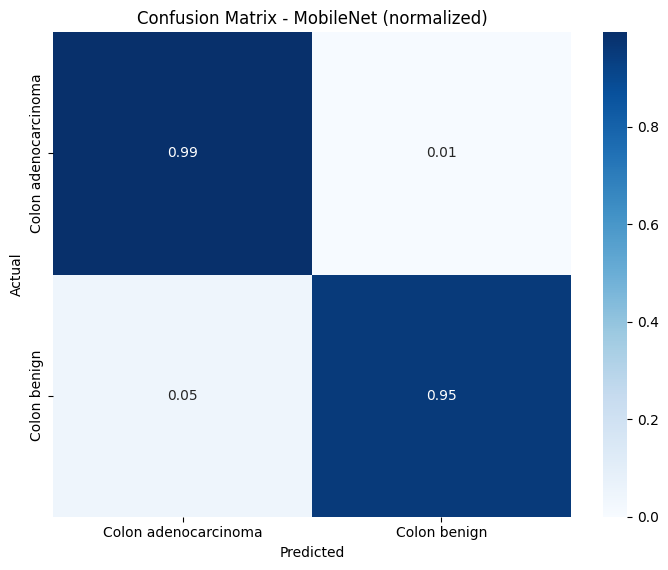

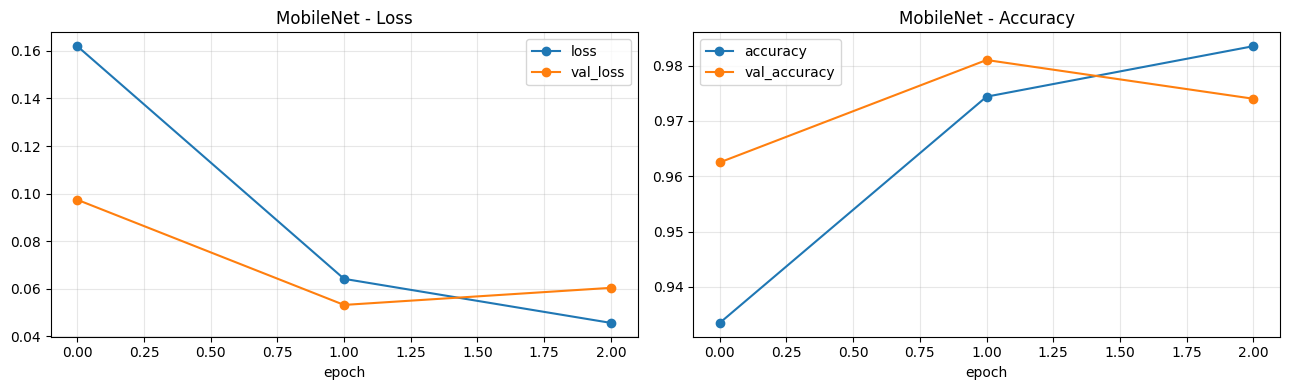


Saved results for [MobileNet] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
accuracy=0.9740  f1_macro=0.9740  auc=0.9991


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon/models/colon_MobileNet.keras


In [ ]:
# ---- Evaluation: MobileNet ----
y_prob = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_val, y_prob, history, train_time,
                 notes='frozen backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 3: **VGG19** - Train

In [ ]:
# ---- Train: VGG19 ----
MODEL_NAME = 'VGG19'
free_memory()

base = VGG19(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False          # frozen backbone, same as the original script

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


t0 = time.time()
history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS[MODEL_NAME],
                    verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,190,402 (77.02 MB)

 Trainable params: 165,250 (645.51 KB)

 Non-trainable params: 20,025,152 (76.39 MB)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 133s 798ms/step - accuracy: 0.9801 - loss: 0.0503 - val_accuracy: 0.9970 - val_loss: 0.0096
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 87s 694ms/step - accuracy: 0.9983 - loss: 0.0077 - val_accuracy: 0.9985 - val_loss: 0.0062
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 86s 693ms/step - accuracy: 0.9989 - loss: 0.0037 - val_accuracy: 0.9980 - val_loss: 0.0068
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 87s 694ms/step - accuracy: 0.9998 - loss: 0.0019 - val_accuracy: 0.9985 - val_loss: 0.0057
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 87s 695ms/step - accuracy: 0.9983 - loss: 0.0049 - val_accuracy: 0.9965 - val_loss: 0.0109
Training time: 8.0 minutes


### Model 3: **VGG19** - Evaluation

32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 560ms/step
                      precision    recall  f1-score   support

Colon adenocarcinoma       1.00      1.00      1.00      1000
        Colon benign       1.00      0.99      1.00      1000

            accuracy                           1.00      2000
           macro avg       1.00      1.00      1.00      2000
        weighted avg       1.00      1.00      1.00      2000



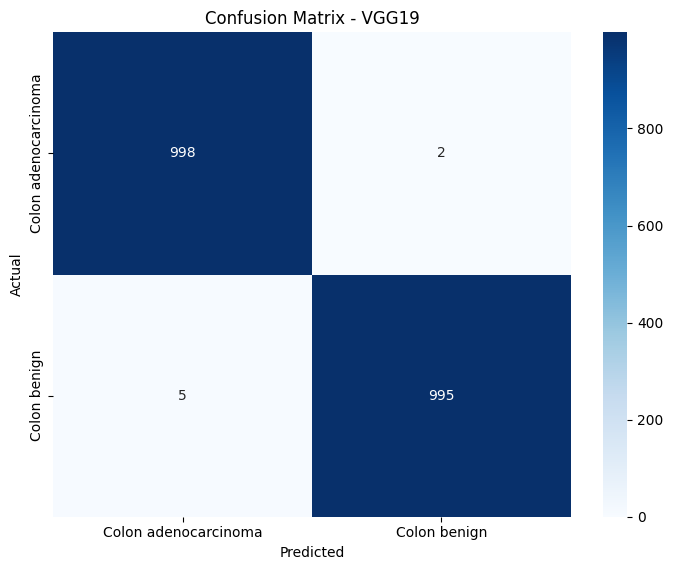

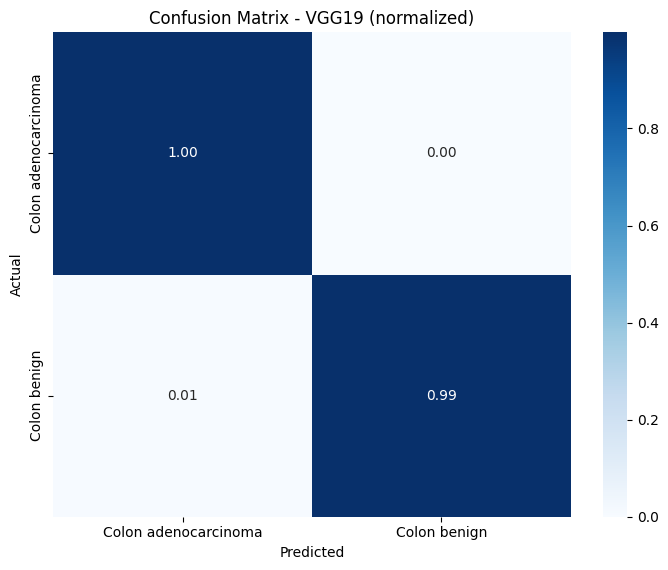

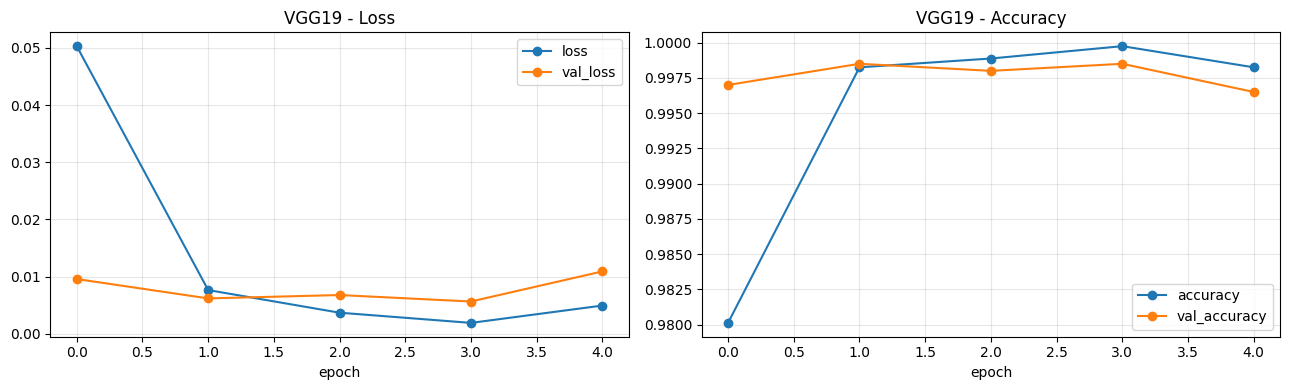


Saved results for [VGG19] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
accuracy=0.9965  f1_macro=0.9965  auc=0.9999


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon/models/colon_VGG19.keras


In [ ]:
# ---- Evaluation: VGG19 ----
y_prob = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_val, y_prob, history, train_time,
                 notes='frozen backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 4: **ResNet50** - Train

In [ ]:
# ---- Train: ResNet50 ----
MODEL_NAME = 'ResNet50'
free_memory()

base = ResNet50(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False          # frozen backbone, same as the original script

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


t0 = time.time()
history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS[MODEL_NAME],
                    verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,146,946 (92.11 MB)

 Trainable params: 558,466 (2.13 MB)

 Non-trainable params: 23,588,480 (89.98 MB)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 57s 319ms/step - accuracy: 0.9868 - loss: 0.0348 - val_accuracy: 0.9845 - val_loss: 0.0434
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 30s 241ms/step - accuracy: 0.9974 - loss: 0.0089 - val_accuracy: 0.9970 - val_loss: 0.0127
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 30s 242ms/step - accuracy: 0.9990 - loss: 0.0049 - val_accuracy: 0.9990 - val_loss: 0.0026
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 30s 242ms/step - accuracy: 0.9991 - loss: 0.0036 - val_accuracy: 0.9990 - val_loss: 0.0042
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 30s 242ms/step - accuracy: 0.9991 - loss: 0.0026 - val_accuracy: 0.9995 - val_loss: 0.0016
Training time: 3.0 minutes


### Model 4: **ResNet50** - Evaluation

32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 305ms/step
                      precision    recall  f1-score   support

Colon adenocarcinoma       1.00      1.00      1.00      1000
        Colon benign       1.00      1.00      1.00      1000

            accuracy                           1.00      2000
           macro avg       1.00      1.00      1.00      2000
        weighted avg       1.00      1.00      1.00      2000



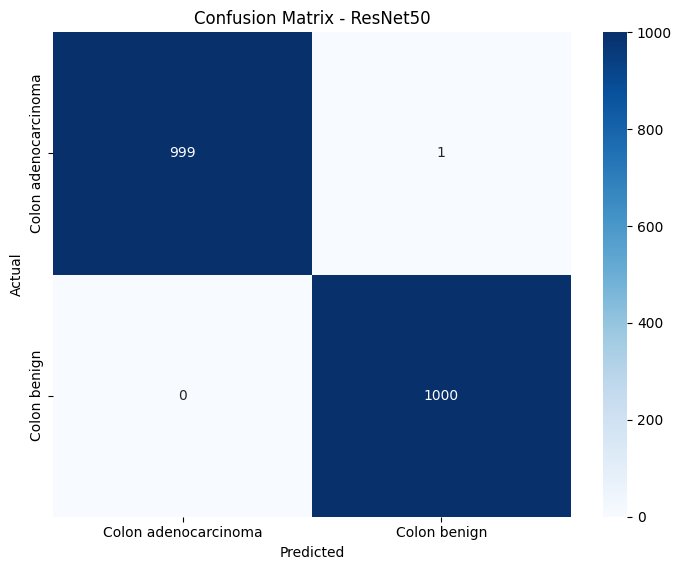

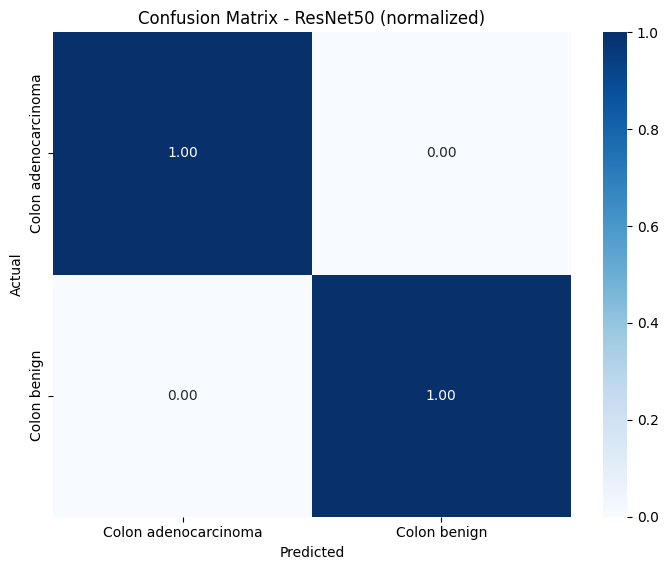

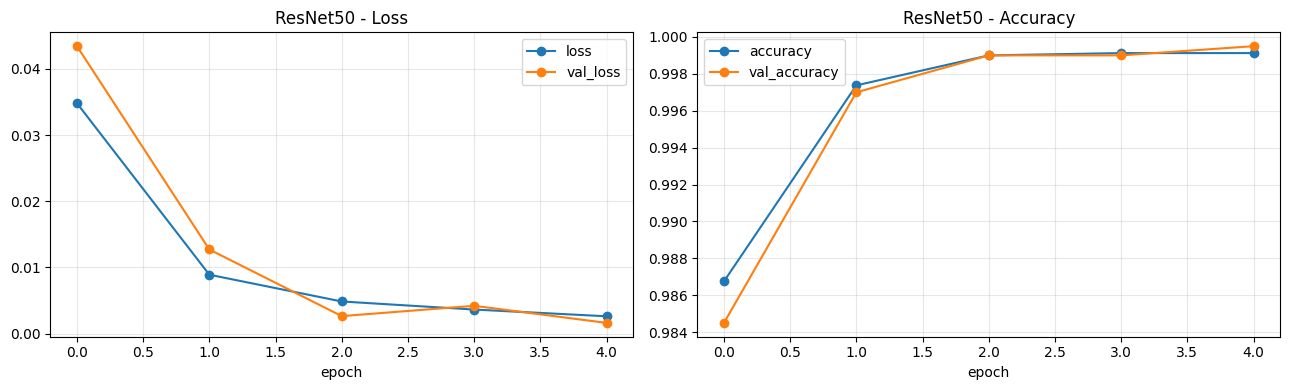


Saved results for [ResNet50] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
accuracy=0.9995  f1_macro=0.9995  auc=1.0000


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon/models/colon_ResNet50.keras


In [ ]:
# ---- Evaluation: ResNet50 ----
y_prob = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_val, y_prob, history, train_time,
                 notes='frozen backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## 8) Model Comparison

,model,accuracy,precision_macro,recall_macro,f1_macro,auc,train_time_sec,total_params
0,ResNet50,0.9995,0.9995,0.9995,0.9995,1.0000,182.4,24146946
1,VGG19,0.9965,0.9965,0.9965,0.9965,0.9999,482.8,20190402
2,MobileNet,0.9740,0.9748,0.9740,0.9740,0.9991,68.0,3525954
3,CNN,0.5000,0.2500,0.5000,0.3333,0.5000,118.6,33684162


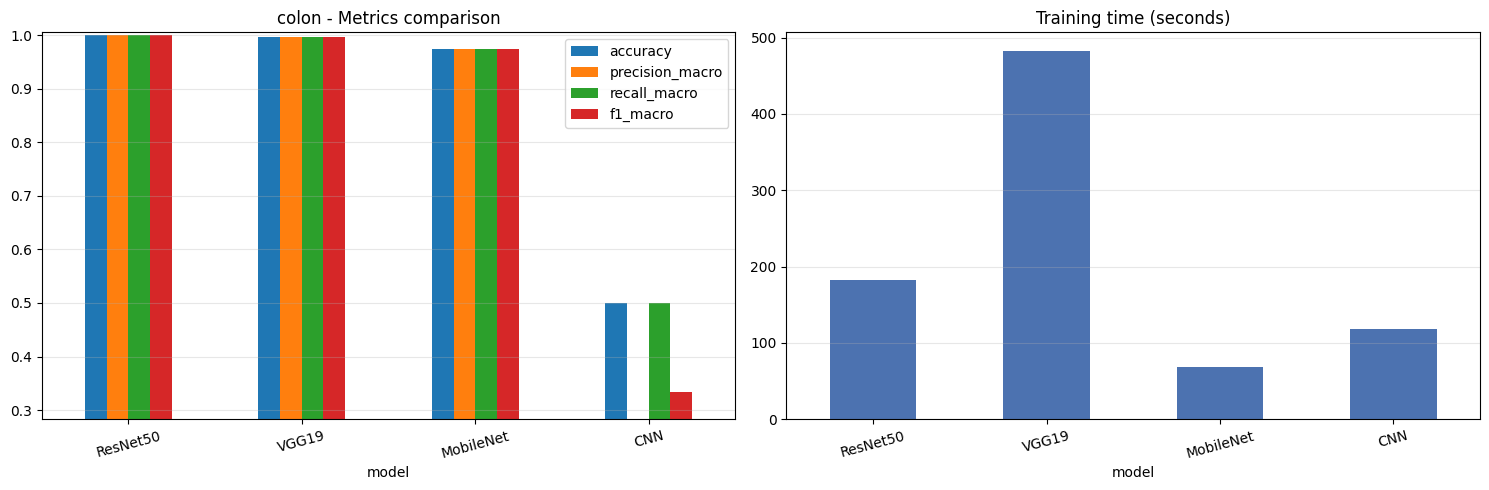

Best model by F1-macro: ResNet50 (accuracy=0.9995, f1=0.9995)


In [ ]:
# ============================================================
#  8) Model Comparison
# ============================================================
comp = pd.read_csv(COMPARISON_CSV)
display(comp[['model', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
              'auc', 'train_time_sec', 'total_params']])

m = comp.set_index('model')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
m[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].plot.bar(ax=ax[0], rot=15)
ax[0].set_ylim(min(0.5, m['f1_macro'].min() - 0.05), 1.005)
ax[0].set_title(f'{CANCER_TYPE} - Metrics comparison'); ax[0].grid(axis='y', alpha=.3)
m[['train_time_sec']].plot.bar(ax=ax[1], rot=15, color='#4c72b0', legend=False)
ax[1].set_title('Training time (seconds)'); ax[1].grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/model_comparison.png', dpi=120)
plt.show()

BEST_MODEL = comp.iloc[0]['model']
print(f'Best model by F1-macro: {BEST_MODEL} '
      f'(accuracy={comp.iloc[0]["accuracy"]:.4f}, f1={comp.iloc[0]["f1_macro"]:.4f})')


## 9) Final Evaluation

=== Final report: ResNet50 ===
                      precision    recall  f1-score   support

Colon adenocarcinoma       1.00      1.00      1.00      1000
        Colon benign       1.00      1.00      1.00      1000

            accuracy                           1.00      2000
           macro avg       1.00      1.00      1.00      2000
        weighted avg       1.00      1.00      1.00      2000



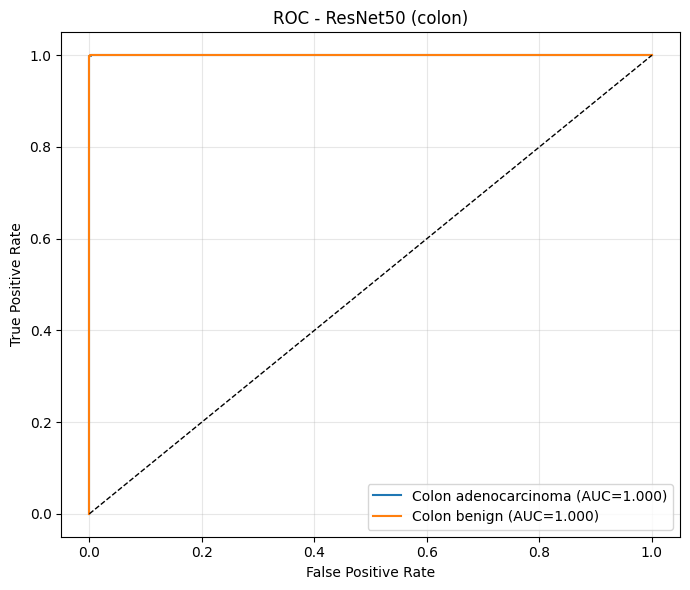

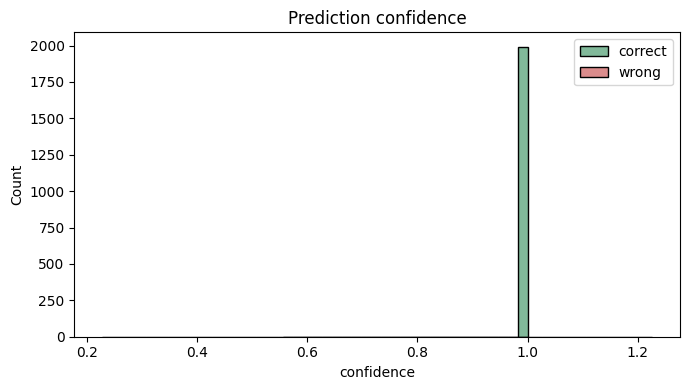

Errors: 1 out of 2000
Mean confidence on wrong predictions: 0.727


In [ ]:
# ============================================================
#  9) Final Evaluation - detailed report for the best model
# ============================================================
best_path = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras'
best_model = tf.keras.models.load_model(best_path)

y_prob_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_prob.npy')
y_true_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_true.npy')
y_pred_best = y_prob_best.argmax(1)

print(f'=== Final report: {BEST_MODEL} ===')
print(metrics.classification_report(y_true_best, y_pred_best,
                                    labels=list(range(NUM_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0))

# Per-class ROC curves
plt.figure(figsize=(7, 6))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = metrics.roc_curve((y_true_best == i).astype(int), y_prob_best[:, i])
    plt.plot(fpr, tpr, label=f'{c} (AUC={metrics.auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title(f'ROC - {BEST_MODEL} ({CANCER_TYPE})'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_roc.png', dpi=120); plt.show()

# Confidence distribution: correct vs wrong predictions
conf = y_prob_best.max(1)
correct = y_pred_best == y_true_best
plt.figure(figsize=(7, 4))
sns.histplot(conf[correct], bins=25, label='correct', color='seagreen', alpha=.6)
sns.histplot(conf[~correct], bins=25, label='wrong', color='indianred', alpha=.7)
plt.xlabel('confidence'); plt.legend(); plt.title('Prediction confidence')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_confidence.png', dpi=120); plt.show()

print(f'Errors: {int((~correct).sum())} out of {len(correct)}')
if (~correct).any():
    print('Mean confidence on wrong predictions: %.3f' % conf[~correct].mean())


## 10) Explainability - Grad-CAM

Red regions are the areas the model relied on. If the model focuses on the background or the image borders instead of the tissue, the problem is in the data rather than in the architecture.

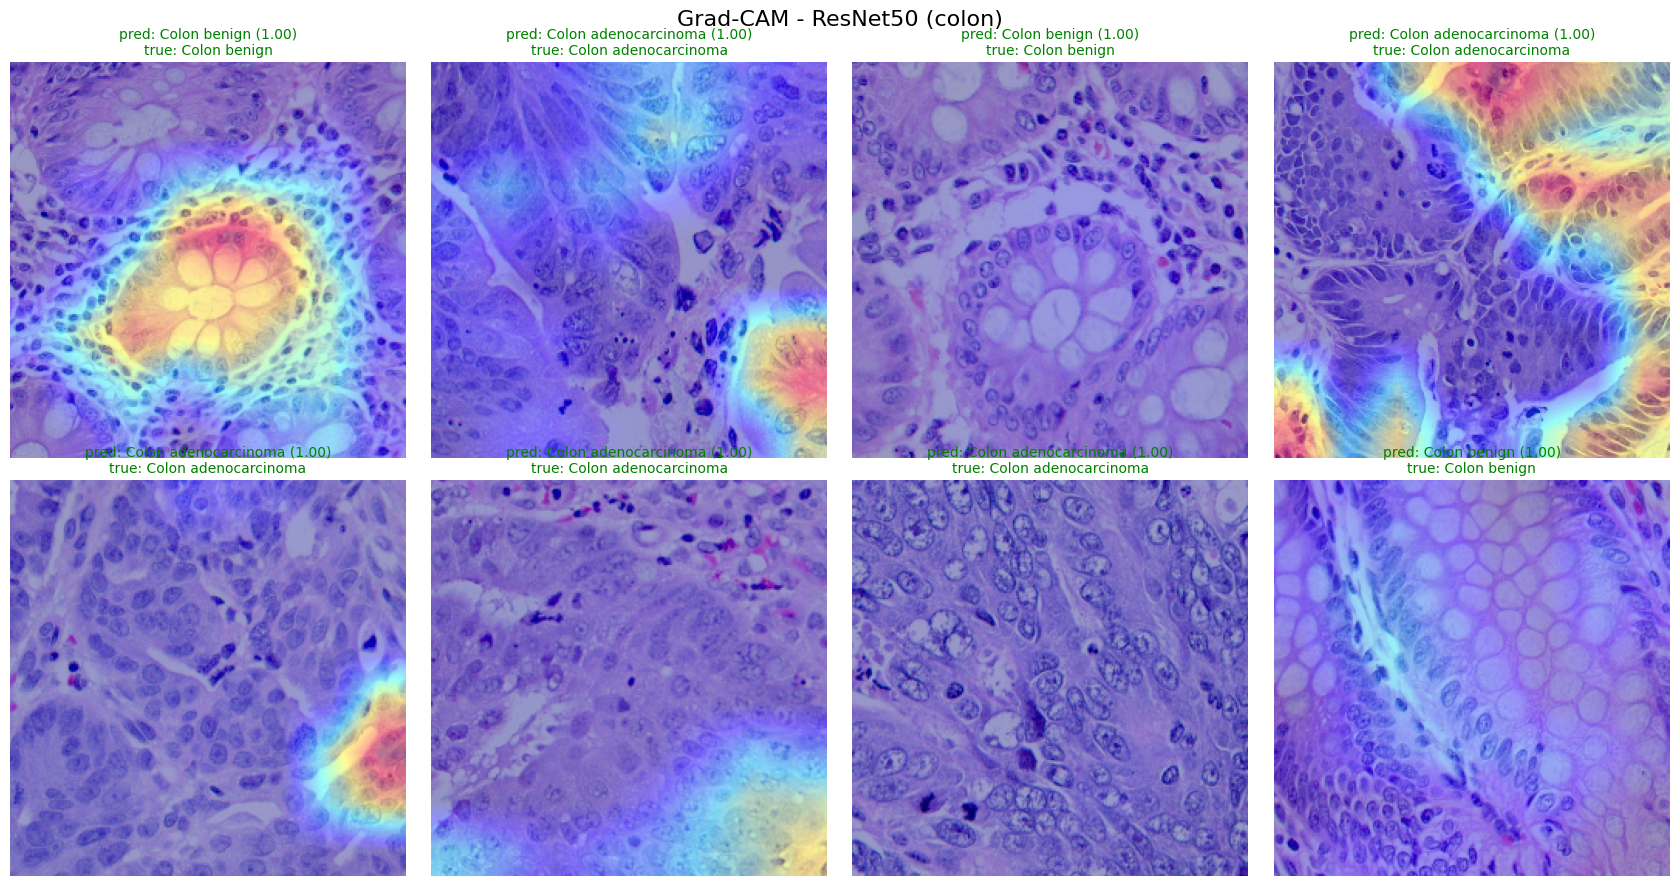

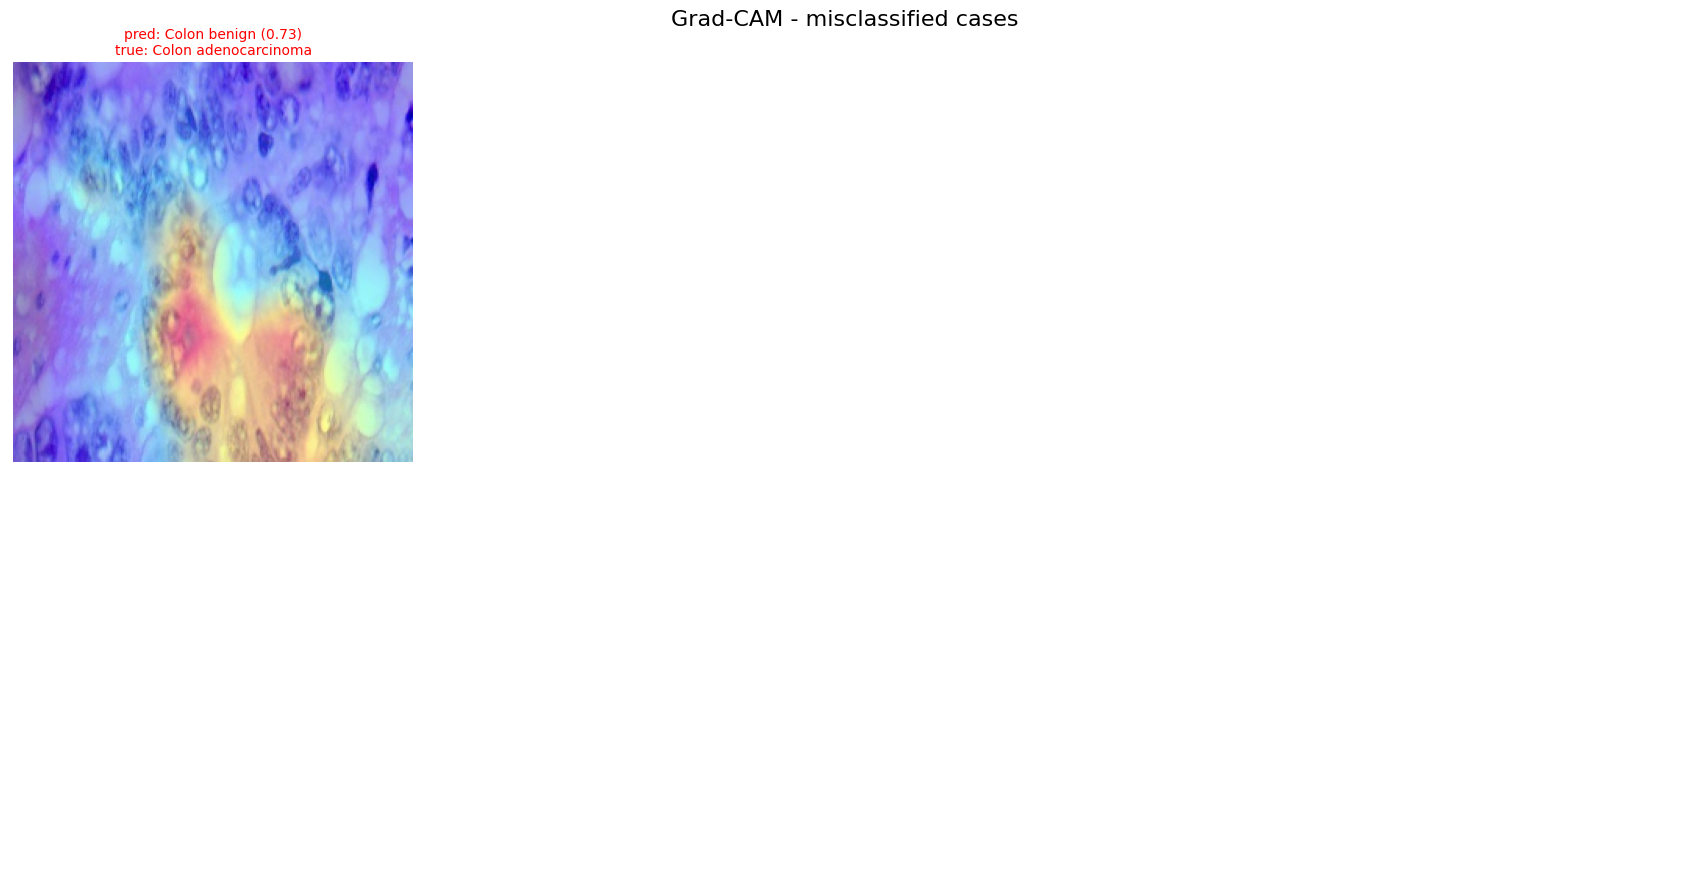

In [ ]:
# ============================================================
#  10) Explainability - Grad-CAM on the best model
# ============================================================
rng = np.random.RandomState(SEED)
idxs = rng.choice(len(X_val), 8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(17, 9))
fig.suptitle(f'Grad-CAM - {BEST_MODEL} ({CANCER_TYPE})', fontsize=16)
for ax, i in zip(axes.ravel(), idxs):
    img = X_val[i]
    disp = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    inp = np.expand_dims(img.astype('float32'), 0)      # same preprocessing as training
    show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_val[i]], ax=ax)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/gradcam_samples.png', dpi=120)
plt.show()

# Misclassified cases - the most informative ones to inspect
wrong = np.where(y_pred_best != y_true_best)[0]
if len(wrong):
    sel = wrong[:8]
    fig, axes = plt.subplots(2, 4, figsize=(17, 9))
    fig.suptitle('Grad-CAM - misclassified cases', fontsize=16)
    for ax, i in zip(axes.ravel(), sel):
        disp = cv2.cvtColor(X_val[i], cv2.COLOR_BGR2RGB)
        inp = np.expand_dims(X_val[i].astype('float32'), 0)
        show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_val[i]], ax=ax)
    for ax in axes.ravel()[len(sel):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/gradcam_errors.png', dpi=120)
    plt.show()
else:
    print('No misclassified samples in the validation set')

## 11) Save Model

In [ ]:
# ============================================================
#  11) Save Model and export a deployment bundle
# ============================================================
DEPLOY_DIR = f'{PROJECT_DIR}/Deploy/{CANCER_TYPE}'
os.makedirs(DEPLOY_DIR, exist_ok=True)

import shutil
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.keras')
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.h5',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.h5')

meta = {
    'cancer_type': CANCER_TYPE,
    'architecture': BEST_MODEL,
    'class_names': CLASS_NAMES,          # exact order of the softmax outputs
    'img_size': IMG_SIZE,
    'preprocessing': PREPROCESS_NAME,    # must match the preprocessing used during training
    'metrics': comp.iloc[0].to_dict(),
    'saved_at': time.strftime('%Y-%m-%d %H:%M:%S'),
}
with open(f'{DEPLOY_DIR}/model_meta.json', 'w') as fh:
    json.dump(meta, fh, indent=2, default=str)

print('Deployment bundle saved to:', DEPLOY_DIR)
for f in sorted(os.listdir(DEPLOY_DIR)):
    print(' -', f)
print('\nAll results:', RESULTS_DIR)
print(' - comparison.csv / all_results.json / summary.xlsx')


Deployment bundle saved to: /content/drive/MyDrive/Colab Notebooks/My Projects/Deploy/colon
 - colon_best.h5
 - colon_best.keras
 - model_meta.json

All results: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/colon
 - comparison.csv / all_results.json / summary.xlsx


In [ ]:
# ============================================================
#  Quick check: predict a single image using the training preprocessing.
#  This is the exact same logic used by the Flask API.
# ============================================================
def predict_image(image_path, model=None, meta_path=f'{DEPLOY_DIR}/model_meta.json'):
    with open(meta_path) as fh:
        meta = json.load(fh)
    model = model or tf.keras.models.load_model(
        f'{DEPLOY_DIR}/{meta["cancer_type"]}_best.keras')
    size = meta['img_size']

    if meta['preprocessing'] == 'bgr_raw':
        # Colon / Lung training: cv2.imread (BGR) + resize, no normalization
        arr = cv2.resize(cv2.imread(image_path), (size, size)).astype('float32')
    else:
        # Leukemia / Skin training: RGB + mobilenet_v2.preprocess_input
        img = load_img(image_path, target_size=(size, size))
        arr = tf.keras.applications.mobilenet_v2.preprocess_input(img_to_array(img))

    arr = np.expand_dims(arr, 0)
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {'label': meta['class_names'][idx],
            'confidence': float(probs[idx]),
            'all_probs': dict(zip(meta['class_names'], probs.round(4).tolist()))}

sample_path = df['filepath'].iloc[0]
print('Image:', os.path.basename(sample_path), '| Ground truth:', df['label'].iloc[0])
predict_image(sample_path)


Image: colonca4710.jpeg | Ground truth: Colon adenocarcinoma


{'label': 'Colon adenocarcinoma',
 'confidence': 0.9999971389770508,
 'all_probs': {'Colon adenocarcinoma': 1.0, 'Colon benign': 0.0}}

---
### Done

Everything is stored under `Results/colon/` and `Deploy/colon/` on Google Drive.

These models are for research and academic use only, not a medical diagnostic tool.